In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    cross_val_predict
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "IBM/telco-customer-churn-on-icp4d/"
    "master/data/Telco-Customer-Churn.csv"
)

df = pd.read_csv(DATA_URL)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

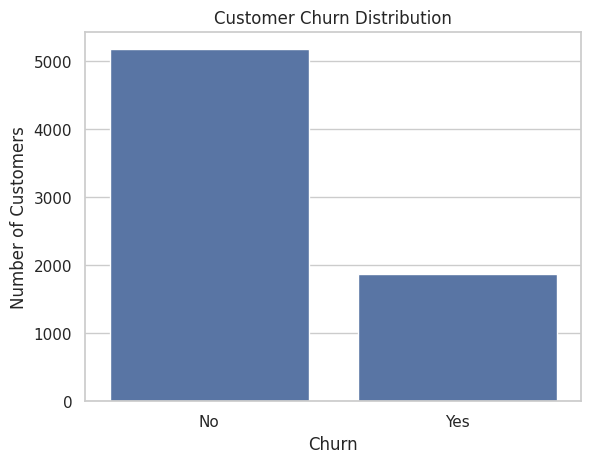

In [4]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

print("\nChurn percentage:")
print(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [6]:
# Remove duplicate records, if any
df = df.drop_duplicates().copy()

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Remove customerID because it is an identifier,
# not a useful customer behavior feature
df = df.drop(columns=["customerID"], errors="ignore")

# Convert target into numeric values
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Remove rows with an invalid target, if any
df = df.dropna(subset=["Churn"]).copy()
df["Churn"] = df["Churn"].astype(int)

print("Data cleaning completed!")
print("Dataset shape:", df.shape)

print("\nMissing values after initial cleaning:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

Data cleaning completed!
Dataset shape: (7043, 20)

Missing values after initial cleaning:
TotalCharges      11
gender             0
Partner            0
SeniorCitizen      0
Dependents         0
tenure             0
MultipleLines      0
PhoneService       0
OnlineSecurity     0
OnlineBackup       0
dtype: int64


In [7]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTotal input features:", X.shape[1])
print("Total customers:", len(X))

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total input features: 19
Total customers: 7043


In [8]:
# Numerical data preprocessing
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical data preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

# Combine both transformers
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training samples: 5634
Testing samples: 1409

Training target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [10]:
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())

if positive_count == 0:
    raise ValueError("Training data contains no churn-positive examples.")

scale_pos_weight = negative_count / positive_count

print("Customers who stayed:", negative_count)
print("Customers who churned:", positive_count)
print("XGBoost scale_pos_weight:", round(scale_pos_weight, 3))

Customers who stayed: 4139
Customers who churned: 1495
XGBoost scale_pos_weight: 2.769


In [13]:
# Random Forest model
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# XGBoost model
xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                n_estimators=300,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=scale_pos_weight,
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train both models
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

print("Random Forest and XGBoost trained successfully!")

Random Forest and XGBoost trained successfully!


In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Check whether required variables exist
print("Checking models...")

# Create models dictionary
models = {
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

# Configure 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Store results
cv_results = {}

# Evaluate both models
for model_name, model in models.items():

    print(f"\nRunning cross-validation for {model_name}...")

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=1
    )

    cv_results[model_name] = scores

    print("Fold ROC-AUC scores:", scores.round(4))
    print("Mean ROC-AUC:", round(scores.mean(), 4))
    print("Standard deviation:", round(scores.std(), 4))

print("\nCross-validation completed successfully!")

Checking models...

Running cross-validation for Random Forest...
Fold ROC-AUC scores: [0.8146 0.8068 0.8272 0.8139 0.8425]
Mean ROC-AUC: 0.821
Standard deviation: 0.0126

Running cross-validation for XGBoost...
Fold ROC-AUC scores: [0.838  0.8273 0.8429 0.8569 0.8503]
Mean ROC-AUC: 0.8431
Standard deviation: 0.0102

Cross-validation completed successfully!


,Model,Mean CV ROC-AUC,Standard Deviation
0,Random Forest,0.821000,0.012605
1,XGBoost,0.843121,0.010172


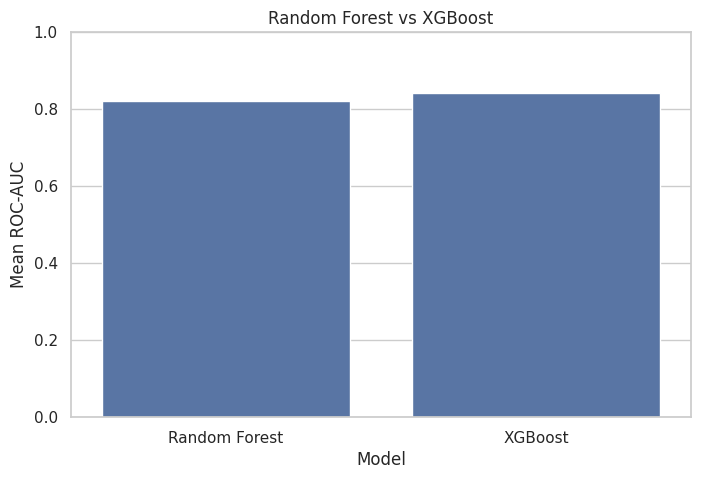

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

comparison = pd.DataFrame({
    "Model": list(cv_results.keys()),
    "Mean CV ROC-AUC": [
        scores.mean() for scores in cv_results.values()
    ],
    "Standard Deviation": [
        scores.std() for scores in cv_results.values()
    ]
})

display(comparison)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Mean CV ROC-AUC"
)

plt.title("Random Forest vs XGBoost")
plt.ylabel("Mean ROC-AUC")
plt.ylim(0, 1)
plt.show()

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

results = []
test_probabilities = {}

models = {
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

for model_name, model in models.items():

    # Predict customer churn
    y_pred = model.predict(X_test)

    # Predict probability of churn
    y_prob = model.predict_proba(X_test)[:, 1]

    test_probabilities[model_name] = y_prob

    # Calculate evaluation metrics
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"\n{'=' * 40}")
    print(model_name)
    print('=' * 40)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["Stayed", "Churned"],
        zero_division=0
    ))

# Display comparison table
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="ROC-AUC",
        ascending=False
    ).reset_index(drop=True)
)


Random Forest
              precision    recall  f1-score   support

      Stayed       0.82      0.90      0.86      1035
     Churned       0.62      0.47      0.53       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.69      1409
weighted avg       0.77      0.78      0.77      1409


XGBoost
              precision    recall  f1-score   support

      Stayed       0.90      0.75      0.82      1035
     Churned       0.53      0.77      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost,0.759404,0.532228,0.772727,0.630316,0.841356
1,Random Forest,0.781405,0.617021,0.465241,0.530488,0.821673


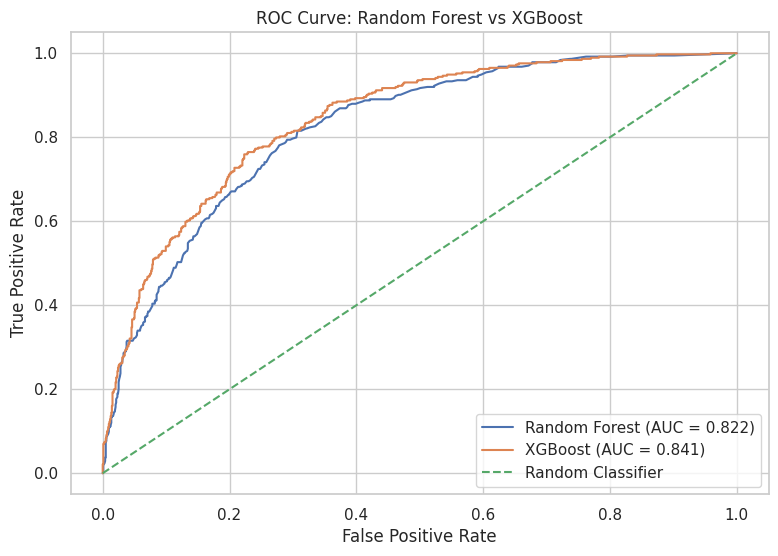

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 6))

for model_name, y_prob in test_probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_score:.3f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Random Forest vs XGBoost")

plt.legend()
plt.show()

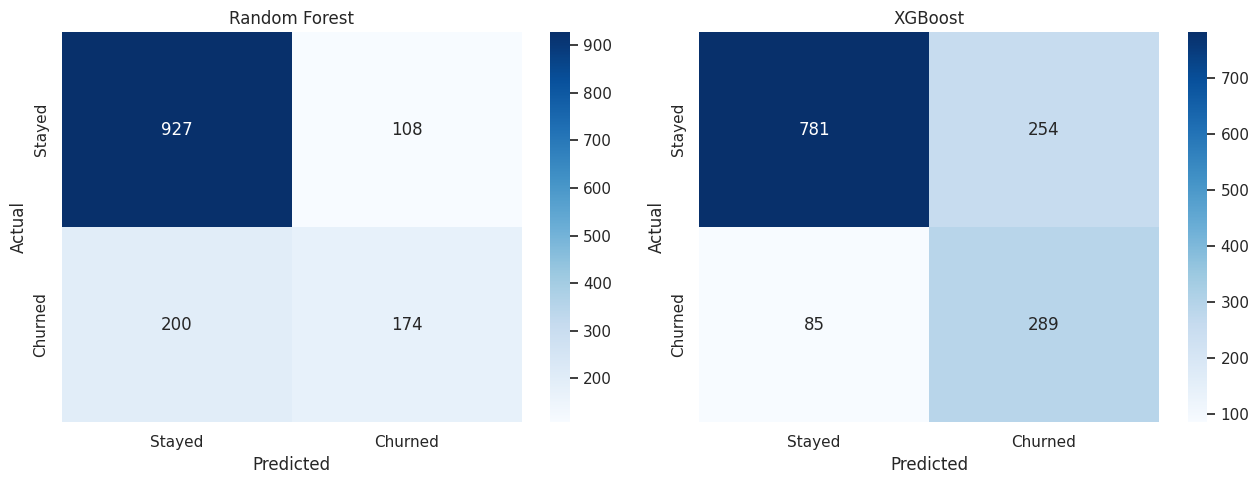

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (model_name, model) in zip(axes, models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Stayed", "Churned"],
        yticklabels=["Stayed", "Churned"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

Top 10 Random Forest Features:


,Feature,Importance
3,num__TotalCharges,0.142224
1,num__tenure,0.130183
2,num__MonthlyCharges,0.123131
36,cat__Contract_Month-to-month,0.073013
18,cat__OnlineSecurity_No,0.037625
38,cat__Contract_Two year,0.035425
27,cat__TechSupport_No,0.032842
43,cat__PaymentMethod_Electronic check,0.028849
16,cat__InternetService_Fiber optic,0.028671
21,cat__OnlineBackup_No,0.016929


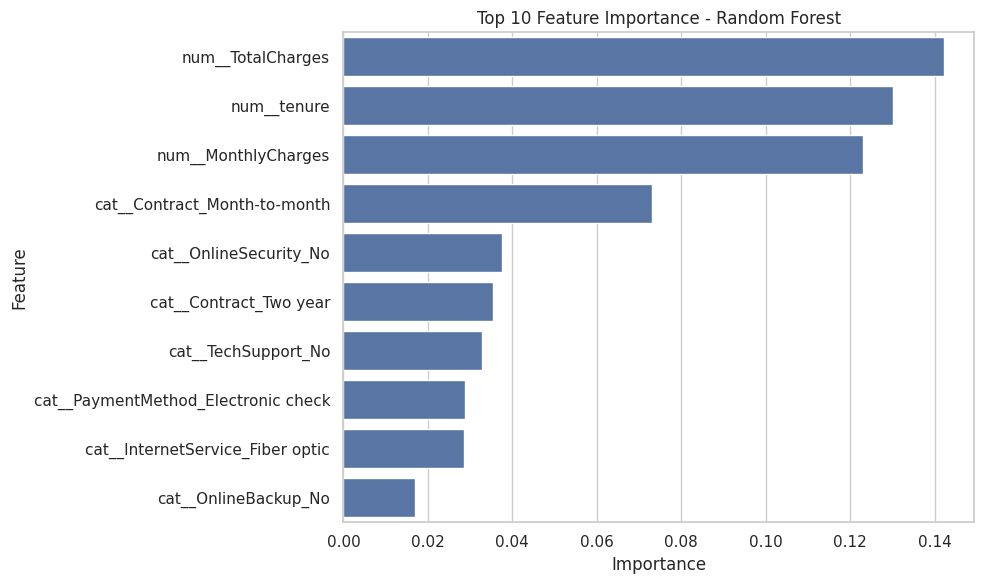

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get trained Random Forest components
rf_preprocessor = rf_model.named_steps["preprocessor"]
rf_classifier = rf_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = rf_preprocessor.get_feature_names_out()

# Calculate feature importance
rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

# Select top 10 features
rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
).head(10)

print("Top 10 Random Forest Features:")
display(rf_importance)

# Plot chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_importance,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [23]:
results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("Final Model Comparison")
display(results_df)

best_model_name = results_df.loc[0, "Model"]

print("\nBest model based on test ROC-AUC:", best_model_name)

best_auc = results_df.loc[0, "ROC-AUC"]

print(f"Best test ROC-AUC: {best_auc:.4f}")

if best_auc >= 0.80:
    print("Target achieved: ROC-AUC is at least 0.80.")
else:
    print("Target not achieved yet: ROC-AUC is below 0.80.")

Final Model Comparison


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost,0.759404,0.532228,0.772727,0.630316,0.841356
1,Random Forest,0.781405,0.617021,0.465241,0.530488,0.821673



Best model based on test ROC-AUC: XGBoost
Best test ROC-AUC: 0.8414
Target achieved: ROC-AUC is at least 0.80.


This project predicts telecom customer churn using two ensemble Machine Learning algorithms: Random Forest and XGBoost. The dataset is cleaned by converting TotalCharges into numeric format and handling missing values. Categorical features are transformed using OneHotEncoder, while class weighting helps address class imbalance.

Both models are evaluated using 5-fold cross-validation, accuracy, precision, recall, F1-score, ROC-AUC curves and confusion matrices. Feature importance charts are used to identify the features that contribute most to the models' predictions.

The final model is selected based on its evaluation results. The project aims to achieve a ROC-AUC score greater than 0.80, although the actual performance depends on the dataset and model configuration.